# PFSP: NEH vs RandNEH (biased randomisation) e ILS-ESP completo

**Problema.** Permutation Flow-Shop Problem, objetivo *makespan*. `p[j,k]` = tiempo del trabajo `j` en la máquina `k`; todos los trabajos pasan por las máquinas en el mismo orden y en el mismo orden de permutación.

**Qué se compara**
1. **Experimento A – solo constructivo.** NEH determinista frente a RandNEH con distintas distribuciones de *biased randomisation* (triangular discreta del PDF, geométrica truncada con varios β, uniforme como control), con el procedimiento exacto de la Fig. 6 de Juan et al. (2014): repite hasta `n` construcciones sesgadas y devuelve la primera que mejora al NEH (nunca es peor que NEH).
2. **Experimento B – ILS-ESP completo** (RandNEH + búsqueda local por inserción + *enhanced swap* + aceptación *Demon*), cambiando solo la inicialización (NEH determinista o RandNEH con distintas distribuciones).

**Instancias** (Taillard): tai001 (20×5), tai051 (50×20), tai081 (100×20), tai101 (200×20), tai117 (500×20). **GAP %** = 100·(valor − BKS)/BKS.

Numba (`@njit`) se usa en makespan, aceleración de Taillard, RandNEH, búsqueda local, operador de perturbación y bucle ILS. Todo el código está en este notebook.

In [1]:
import os, time, math, warnings
from dataclasses import dataclass
from pathlib import Path
import multiprocessing as mp

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numba import njit
from scipy import stats

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

# --- parámetros del estudio (cambiar aquí para ampliar/reducir el coste) ---
DATA_DIR   = Path("../data") if Path("../data").exists() else Path("data")
RESULTS_DIR = Path("../results") if Path("../results").exists() else Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
INSTANCES  = ["tai001_20_5", "tai051_50_20", "tai081_100_20", "tai101_200_20", "tai117_500_20"]
N_REPS_A   = 30       # ejecuciones de RandNEH por (instancia, distribución); cada una usa hasta n construcciones
N_SEEDS_B  = 10       # ejecuciones independientes de ILS-ESP por (instancia, inicialización)
TIME_FACTOR = 2.0     # ms por (n·m) de presupuesto de ILS-ESP (el PDF usa 10 ms·n·m)
N_PROCS    = min(2, os.cpu_count() or 1)
BASE_SEED  = 2024
RERUN      = False    # False: se leen los resultados guardados en results/; True: se vuelven a ejecutar los experimentos

BKS = {"tai001_20_5": 1278, "tai051_50_20": 3846, "tai081_100_20": 6171,
       "tai101_200_20": 11158, "tai117_500_20": 26389}
PROVEN_OPTIMAL = {"tai101_200_20", "tai117_500_20"}   # columna Optimal=1 del CSV de Zenodo
def gap_pct(v, bks): return 100.0 * (np.asarray(v, dtype=float) - bks) / bks

## 1. Instancias y BKS
`BKS` sale de la tabla de Taillard (tai001: UB 1278) y del CSV de Zenodo (resto). Solo tai101 y tai117 están demostradas óptimas; en tai001, tai051 y tai081 el BKS es el mejor valor conocido, así que un GAP ligeramente negativo sería posible en teoría (no esperable).

In [2]:
def read_instance(path):
    rows = []
    for line in Path(path).read_text().splitlines():
        line = line.strip()
        if line and not line.startswith("#"):
            rows.append([int(x) for x in line.split()])
    (n, m), data = rows[0], rows[1:]
    assert len(data) == n and all(len(r) == m for r in data), f"{path}: dimensiones inconsistentes"
    return np.array(data, dtype=np.int64)

P = {name: read_instance(DATA_DIR / f"{name}_inputs.txt") for name in INSTANCES}
pd.DataFrame({
    "instancia": INSTANCES,
    "n": [P[k].shape[0] for k in INSTANCES], "m": [P[k].shape[1] for k in INSTANCES],
    "BKS": [BKS[k] for k in INSTANCES],
    "BKS óptimo demostrado": [k in PROVEN_OPTIMAL for k in INSTANCES],
})

,instancia,n,m,BKS,BKS óptimo demostrado
0,tai001_20_5,20,5,1278,False
1,tai051_50_20,50,20,3846,False
2,tai081_100_20,100,20,6171,False
3,tai101_200_20,200,20,11158,True
4,tai117_500_20,500,20,26389,True


## 2. Núcleo en Numba: makespan y aceleración de Taillard

* `calc_makespan`: recurrencia `C[i][k] = max(C[i-1][k], C[i][k-1]) + p`, O(n·m).
* `insert_best_position`: mueve el trabajo `perm[k]` a la mejor posición dentro de `perm[0..k]` en O(k·m) con las matrices `e` (hacia delante), `q` (hacia atrás) y `f` (trabajo nuevo). Desempate: posición más a la izquierda (como el PDF).

In [3]:
@njit(cache=True)
def calc_makespan(p, perm, length):
    m = p.shape[1]
    c = np.zeros(m, dtype=np.int64)
    for i in range(length):
        job = perm[i]
        c[0] += p[job, 0]
        for k in range(1, m):
            c[k] = max(c[k], c[k - 1]) + p[job, k]
    return c[m - 1]

@njit(cache=True)
def insert_best_position(p, perm, k):
    m = p.shape[1]
    new = perm[k]
    e = np.empty((k, m), dtype=np.int64)
    for i in range(k):
        job = perm[i]
        for j in range(m):
            if i == 0 and j == 0:
                e[0, 0] = p[job, 0]
            elif j == 0:
                e[i, 0] = e[i - 1, 0] + p[job, 0]
            elif i == 0:
                e[0, j] = e[0, j - 1] + p[job, j]
            else:
                e[i, j] = max(e[i - 1, j], e[i, j - 1]) + p[job, j]
    q = np.zeros((k + 1, m), dtype=np.int64)
    for i in range(k - 1, -1, -1):
        job = perm[i]
        for j in range(m - 1, -1, -1):
            if j == m - 1:
                q[i, j] = q[i + 1, j] + p[job, j]
            else:
                q[i, j] = max(q[i + 1, j], q[i, j + 1]) + p[job, j]
    best_pos = 0
    best_mk = np.int64(1) << 62
    for i in range(k + 1):
        mk_i = np.int64(0)
        f_prev = np.int64(0)
        for j in range(m):
            above = e[i - 1, j] if i > 0 else np.int64(0)
            f_ij = above + p[new, 0] if j == 0 else max(above, f_prev) + p[new, j]
            f_prev = f_ij
            tot = f_ij + q[i, j]
            if tot > mk_i:
                mk_i = tot
        if mk_i < best_mk:          # '<' estricto -> gana la posición más a la izquierda
            best_mk = mk_i
            best_pos = i
    for i in range(k, best_pos, -1):
        perm[i] = perm[i - 1]
    perm[best_pos] = new
    return best_mk

def makespan_slow(p, perm):
    # verificación independiente en Python puro
    n, m = len(perm), p.shape[1]
    C = np.zeros((n, m), dtype=np.int64)
    for i, j_ in enumerate(perm):
        for k in range(m):
            up = C[i-1, k] if i else 0
            left = C[i, k-1] if k else 0
            C[i, k] = max(up, left) + p[j_, k]
    return int(C[-1, -1])

## 3. RandNEH con *biased randomisation*

NEH ordena los trabajos por tiempo total de procesamiento (TPT) decreciente. **RandNEH** (Juan et al.) no toma siempre el primero de los que quedan: elige la posición `pos` de esa lista con una distribución sesgada hacia las primeras posiciones. Las distribuciones, con `r` = nº de trabajos que quedan:

| Código | Distribución | `pos` |
|---|---|---|
| `NEH` | determinista (β→1) | `0` |
| `Tri` | triangular decreciente discretizada (la del PDF, sin parámetros) | `floor(r·(1−√(1−u)))` |
| `Geo(β)` | geométrica truncada a `r` posiciones | `floor(ln(1−u·(1−(1−β)^r))/ln(1−β))` |
| `Unif` | uniforme (control: sin sesgo) | `floor(r·u)` |

**RandNEH del paper (Fig. 6).** No es una única construcción: se calcula el NEH; después, mientras la mejor solución no sea estrictamente mejor que el NEH y se hayan hecho menos de `n` intentos, se construye una solución sesgada y se conserva si mejora. Devuelve la primera que gana al NEH o, si ninguna lo logra en `n` intentos, el propio NEH. En el código: `rand_neh` hace una construcción sesgada y `rand_neh_paper` es el bucle de la Fig. 6, que es el RandNEH que se evalúa.

Nota: el PDF da `X = b·(1−√(1−u))` sin definir `b` (el texto del paper dice que las probabilidades decrecen linealmente y dependen del nº de trabajos elegibles, coherente con `b = r`); aquí `b = r` (supuesto). Con esa `b` la triangular es poco concentrada cuando `r` es grande (posición media ≈ r/3), mientras que la geométrica con β fijo mantiene el mismo sesgo para cualquier `r`.

In [4]:
KIND_NEH, KIND_UNIF, KIND_TRI, KIND_GEO = 0, 1, 2, 3

@njit(cache=True)
def seed_numba(s):
    np.random.seed(s)

@njit(cache=True)
def sample_pos(r, kind, beta):
    u = np.random.random()
    if kind == KIND_NEH:
        return 0
    if kind == KIND_UNIF:
        pos = int(r * u)
    elif kind == KIND_TRI:
        pos = int(r * (1.0 - np.sqrt(1.0 - u)))
    else:
        lb = np.log(1.0 - beta)
        tail = (1.0 - beta) ** r
        pos = int(np.log(1.0 - u * (1.0 - tail)) / lb)
    return min(pos, r - 1)

@njit(cache=True)
def sample_many(r, kind, beta, N):
    out = np.empty(N, dtype=np.int64)
    for i in range(N):
        out[i] = sample_pos(r, kind, beta)
    return out

@njit(cache=True)
def rand_neh(p, order, kind, beta):
    # order: trabajos por TPT decreciente. Devuelve (perm, makespan).
    n = order.shape[0]
    remaining = order.copy()
    perm = np.empty(n, dtype=np.int64)
    mk = np.int64(0)
    r = n
    for step in range(n):
        pos = sample_pos(r, kind, beta)
        perm[step] = remaining[pos]
        for t in range(pos, r - 1):      # eliminar de la lista
            remaining[t] = remaining[t + 1]
        r -= 1
        if step == 0:
            mk = calc_makespan(p, perm, 1)
        else:
            mk = insert_best_position(p, perm, step)
    return perm, mk

@njit(cache=True)
def rand_neh_paper(p, order, kind, beta):
    # Fig. 6 de Juan et al. (2014). Devuelve (perm, makespan, nº de construcciones sesgadas).
    n = order.shape[0]
    neh_perm, neh_mk = rand_neh(p, order, KIND_NEH, 0.0)
    if kind == KIND_NEH:
        return neh_perm, neh_mk, 1
    best_perm = neh_perm.copy()
    best_mk = neh_mk
    tries = 0
    while best_mk >= neh_mk and tries < n:
        tries += 1
        perm, mk = rand_neh(p, order, kind, beta)
        if mk < best_mk:
            best_perm = perm.copy()
            best_mk = mk
    return best_perm, best_mk, tries

def tpt_order(p):
    return np.argsort(-p.sum(axis=1), kind="stable").astype(np.int64)   # desempate: ID menor primero

# (nombre, kind, beta) -- configuraciones estudiadas
CONFIGS = [("NEH", KIND_NEH, 0.0), ("Tri", KIND_TRI, 0.0),
           ("Geo(0.05)", KIND_GEO, 0.05), ("Geo(0.1)", KIND_GEO, 0.1), ("Geo(0.2)", KIND_GEO, 0.2),
           ("Geo(0.3)", KIND_GEO, 0.3), ("Geo(0.5)", KIND_GEO, 0.5), ("Unif", KIND_UNIF, 0.0)]
CFG = {c[0]: c for c in CONFIGS}

# Experimento A: NEH y RandNEH del paper con cada distribución (el último campo indica si se usa el bucle de la Fig. 6)
CONFIGS_A = [(c[0], c[1], c[2], c[0] != "NEH") for c in CONFIGS]

# calentamiento de la compilación
_p = P["tai001_20_5"]; seed_numba(0)
_ = [rand_neh(_p, tpt_order(_p), c[1], c[2]) for c in CONFIGS]
_ = rand_neh_paper(_p, tpt_order(_p), KIND_TRI, 0.0)

### 3.1 Validación
Antes de experimentar: (i) NEH con aceleración de Taillard = NEH ingenuo con recurrencia directa; (ii) el makespan devuelto por RandNEH coincide con el recalculado desde cero; (iii) tai117 reproduce el valor del PDF (26797 con el NEH determinista).

In [5]:
def neh_naive(p):
    # NEH sin aceleración: prueba cada posición con la recurrencia directa (lento, solo para validar)
    perm = []
    for job in tpt_order(p):
        best, best_pos = None, 0
        for pos in range(len(perm) + 1):
            cand = perm[:pos] + [int(job)] + perm[pos:]
            v = makespan_slow(p, cand)
            if best is None or v < best:
                best, best_pos = v, pos
        perm.insert(best_pos, int(job))
    return perm, best

for name in ["tai001_20_5", "tai051_50_20"]:
    p = P[name]
    perm, mk = rand_neh(p, tpt_order(p), KIND_NEH, 0.0)
    perm_ref, mk_ref = neh_naive(p)
    assert list(perm) == perm_ref and mk == mk_ref, name
    print(f"{name}: NEH acelerado == NEH ingenuo  (makespan {mk})")

seed_numba(1)
for name in INSTANCES:
    p = P[name]
    for cfg in CONFIGS:
        perm, mk = rand_neh(p, tpt_order(p), cfg[1], cfg[2])
        assert sorted(perm) == list(range(p.shape[0])) and mk == makespan_slow(p, perm)
for name in INSTANCES:
    p = P[name]; neh_mk = rand_neh(p, tpt_order(p), KIND_NEH, 0.0)[1]
    for cfg in CONFIGS[1:]:
        perm, mk, tries = rand_neh_paper(p, tpt_order(p), cfg[1], cfg[2])
        assert sorted(perm) == list(range(p.shape[0])) and mk == makespan_slow(p, perm) and mk <= neh_mk and 1 <= tries <= p.shape[0]
print("RandNEH: permutaciones válidas y makespan verificado para todas las instancias y distribuciones")
print("RandNEH del paper: válido y nunca peor que NEH en todas las instancias y distribuciones")

p = P["tai117_500_20"]
mk117 = rand_neh(p, tpt_order(p), KIND_NEH, 0.0)[1]
print("NEH tai117 =", mk117, "(PDF: 26797)")
assert mk117 == 26797

tai001_20_5: NEH acelerado == NEH ingenuo  (makespan 1286)


tai051_50_20: NEH acelerado == NEH ingenuo  (makespan 4082)


RandNEH: permutaciones válidas y makespan verificado para todas las instancias y distribuciones
RandNEH del paper: válido y nunca peor que NEH en todas las instancias y distribuciones
NEH tai117 = 26797 (PDF: 26797)


### 3.2 Cómo reparte cada distribución la probabilidad entre los candidatos
Probabilidad de elegir cada posición de la lista ordenada por TPT, con `r = 20` y `r = 100` candidatos.

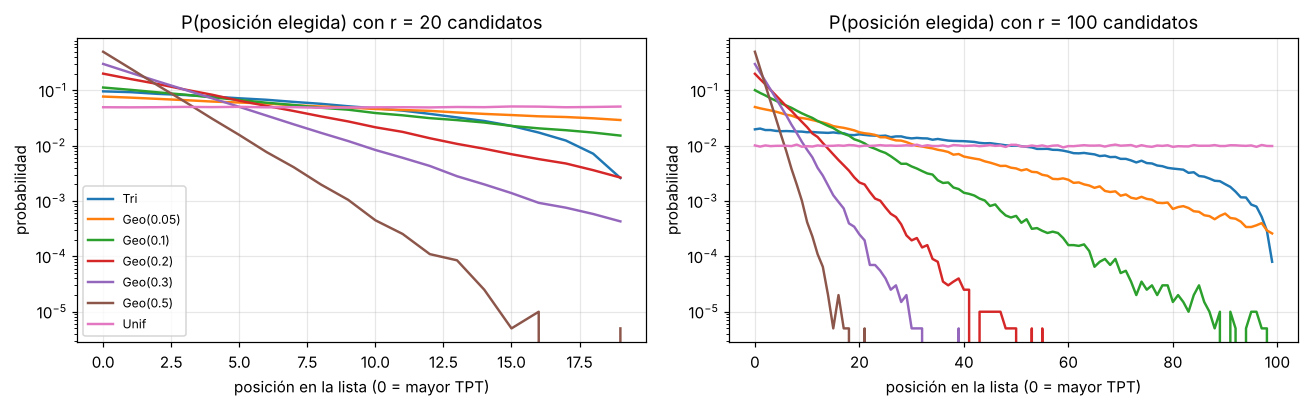

Posición media elegida (0 = el primero de la lista):


,Tri,Geo(0.05),Geo(0.1),Geo(0.2),Geo(0.3),Geo(0.5),Unif
r,,,,,,,
20,6.19,7.82,6.23,3.76,2.33,1.0,9.50
100,32.75,18.35,9.02,4.01,2.34,1.0,49.51
500,165.64,19.07,8.98,4.00,2.32,1.0,249.67


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
seed_numba(7)
for ax, r in zip(axes, [20, 100]):
    for name, kind, beta in CONFIGS[1:]:
        s = sample_many(r, kind, beta, 200_000)
        pmf = np.bincount(s, minlength=r) / len(s)
        ax.plot(range(r), pmf, label=name, lw=1.6)
    ax.set_title(f"P(posición elegida) con r = {r} candidatos"); ax.set_xlabel("posición en la lista (0 = mayor TPT)")
    ax.set_yscale("log"); ax.set_ylabel("probabilidad")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

rows = []
for r in [20, 100, 500]:
    row = {"r": r}
    for name, kind, beta in CONFIGS[1:]:
        row[name] = sample_many(r, kind, beta, 200_000).mean()
    rows.append(row)
print("Posición media elegida (0 = el primero de la lista):")
pd.DataFrame(rows).set_index("r").round(2)

## 4. Experimento A – RandNEH frente a NEH (solo fase constructiva)

Para cada instancia y distribución se hacen `N_REPS_A` ejecuciones del procedimiento de la Fig. 6 (cada una usa hasta `n` construcciones; `construcciones_medias` dice cuántas hizo). NEH es determinista (una solución). Métricas: GAP medio y desviación, mejor GAP, y % de ejecuciones que mejoran al NEH.

In [7]:
def run_A():
    rows, raw = [], []
    for name in INSTANCES:
        p = P[name]; order = tpt_order(p); bks = BKS[name]
        neh_mk = rand_neh(p, order, KIND_NEH, 0.0)[1]
        for ci, (cname, kind, beta, paper) in enumerate(CONFIGS_A):
            seed_numba(BASE_SEED + 1000 * ci)
            reps = 1 if kind == KIND_NEH else N_REPS_A
            mks = np.empty(reps, dtype=np.int64); tr = np.ones(reps)
            t0 = time.perf_counter()
            for i in range(reps):
                if paper:
                    _, mks[i], t_ = rand_neh_paper(p, order, kind, beta); tr[i] = t_
                else:
                    mks[i] = rand_neh(p, order, kind, beta)[1]
            dt = (time.perf_counter() - t0) / reps * 1000
            g = gap_pct(mks, bks)
            rows.append(dict(instancia=name, dist=cname, reps=reps, gap_medio=g.mean(), gap_std=g.std(ddof=0),
                             gap_mejor=g.min(), gap_peor=g.max(), pct_mejora_NEH=100 * np.mean(mks < neh_mk),
                             construcciones_medias=tr.mean(),
                             ms_por_ejecucion=dt, makespan_NEH=neh_mk))
            raw += [dict(instancia=name, dist=cname, makespan=int(v), gap=float(x)) for v, x in zip(mks, g)]
    return pd.DataFrame(rows), pd.DataFrame(raw)

if RERUN:
    resA, rawA = run_A()
    resA.to_csv(RESULTS_DIR / "expA_randneh_resumen.csv", index=False)
    rawA.to_csv(RESULTS_DIR / "expA_randneh_raw.csv", index=False)
else:   # resultados guardados de la última ejecución (se descartan las filas de la versión de una construcción)
    resA = pd.read_csv(RESULTS_DIR / "expA_randneh_resumen.csv"); rawA = pd.read_csv(RESULTS_DIR / "expA_randneh_raw.csv")
    resA = resA[(resA.dist == "NEH") | resA.dist.str.endswith("(paper)")].copy()
    rawA = rawA[(rawA.dist == "NEH") | rawA.dist.str.endswith("(paper)")].copy()
    resA["dist"] = resA.dist.str.replace(" (paper)", "", regex=False); rawA["dist"] = rawA.dist.str.replace(" (paper)", "", regex=False)
tabA = resA.pivot(index="dist", columns="instancia", values="gap_medio").reindex([c[0] for c in CONFIGS_A])[INSTANCES]
print("GAP medio (%) de la solución constructiva:")
tabA.round(3)

GAP medio (%) de la solución constructiva:


instancia,tai001_20_5,tai051_50_20,tai081_100_20,tai101_200_20,tai117_500_20
dist,,,,,
NEH,0.626,6.136,5.996,3.908,1.546
Tri,0.420,5.502,5.705,3.780,1.457
Geo(0.05),0.524,5.653,5.740,3.722,1.442
Geo(0.1),0.383,5.525,5.718,3.749,1.456
Geo(0.2),0.355,5.417,5.695,3.780,1.413
Geo(0.3),0.211,5.304,5.700,3.699,1.400
Geo(0.5),0.112,5.452,5.714,3.702,1.410
Unif,0.535,5.694,5.843,3.780,1.472


In [8]:
resA.pivot_table(index="dist", columns="instancia", values=["gap_medio", "gap_mejor", "pct_mejora_NEH", "construcciones_medias", "ms_por_ejecucion"]) \
    .reindex([c[0] for c in CONFIGS_A], level=0).round(2)

construcciones_medias                                           \
instancia           tai001_20_5 tai051_50_20 tai081_100_20 tai101_200_20   
dist                                                                       
NEH                        1.00         1.00          1.00          1.00   
Tri                       14.47         3.17         14.03         19.03   
Geo(0.05)                 18.07         3.20         15.47         16.33   
Geo(0.1)                  13.80         2.77          7.70         10.97   
Geo(0.2)                  14.53         2.30          5.63          8.93   
Geo(0.3)                   9.90         1.50          3.60          6.60   
Geo(0.5)                   6.63         1.33          6.03          6.33   
Unif                      16.97         3.60         40.73         97.17   

                          gap_medio                                           \
instancia tai117_500_20 tai001_20_5 tai051_50_20 tai081_100_20 tai101_200_20   
dist                                                                           
NEH                1.00        0.63         6.14          6.00          3.91   
Tri                8.63        0.42         5.50          5.70          3.78   
Geo(0.05)          3.03        0.52         5.65          5.74          3.72   
Geo(0.1)           2.07        0.38         5.53          5.72          3.75   
Geo(0.2)           2.80        0.35         5.42          5.70          3.78   
Geo(0.3)           1.80        0.21         5.30          5.70          3.70   
Geo(0.5)           3.20        0.11         5.45          5.71          3.70   
Unif             114.90        0.53         5.69          5.84          3.78   

                         ... ms_por_ejecucion                             \
instancia tai117_500_20  ...      tai001_20_5 tai051_50_20 tai081_100_20   
dist                     ...                                               
NEH                1.55  ...             0.02         0.24          0.66   
Tri                1.46  ...             0.19         0.81         12.26   
Geo(0.05)          1.44  ...             0.26         0.89         13.00   
Geo(0.1)           1.46  ...             0.21         0.76          6.01   
Geo(0.2)           1.41  ...             0.18         0.88          4.44   
Geo(0.3)           1.40  ...             0.18         0.69          3.05   
Geo(0.5)           1.41  ...             0.12         0.58          4.91   
Unif               1.47  ...             0.25         0.86         29.31   

                                      pct_mejora_NEH               \
instancia tai101_200_20 tai117_500_20    tai001_20_5 tai051_50_20   
dist                                                                
NEH                2.51         12.32           0.00          0.0   
Tri               53.63        152.12          50.00        100.0   
Geo(0.05)         45.56         61.57          33.33        100.0   
Geo(0.1)          31.82         46.14          56.67        100.0   
Geo(0.2)          31.38         48.97          56.67        100.0   
Geo(0.3)          20.62         39.48          86.67        100.0   
Geo(0.5)          20.35         57.03          96.67        100.0   
Unif             293.15       1750.21          30.00        100.0   

                                                     
instancia tai081_100_20 tai101_200_20 tai117_500_20  
dist                                                 
NEH                0.00          0.00           0.0  
Tri              100.00        100.00         100.0  
Geo(0.05)        100.00        100.00         100.0  
Geo(0.1)         100.00        100.00         100.0  
Geo(0.2)         100.00        100.00         100.0  
Geo(0.3)         100.00        100.00         100.0  
Geo(0.5)         100.00        100.00         100.0  
Unif              86.67         83.33         100.0  

[8 rows x 25 columns]

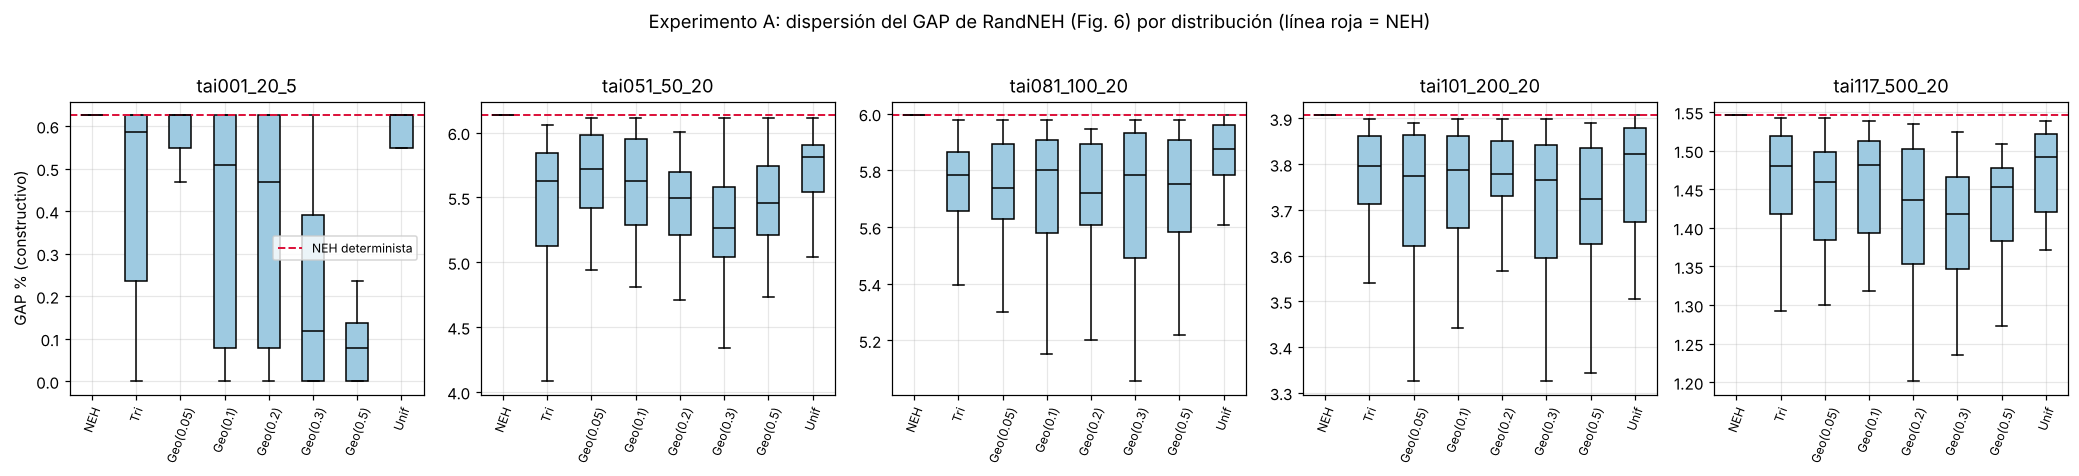

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(19, 4.2))
order_names = [c[0] for c in CONFIGS_A]
for ax, name in zip(axes, INSTANCES):
    d = rawA[rawA.instancia == name]
    data = [d[d.dist == c].gap.values for c in order_names]
    ax.boxplot(data, tick_labels=order_names, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor="#9ecae1"), medianprops=dict(color="k"))
    neh_gap = d[d.dist == "NEH"].gap.iloc[0]
    ax.axhline(neh_gap, color="crimson", ls="--", lw=1.3, label="NEH determinista")
    ax.set_title(name); ax.tick_params(axis="x", rotation=70, labelsize=8)
    ax.set_ylabel("GAP % (constructivo)" if name == INSTANCES[0] else "")
axes[0].legend(fontsize=8)
plt.suptitle("Experimento A: dispersión del GAP de RandNEH (Fig. 6) por distribución (línea roja = NEH)", y=1.02)
plt.tight_layout(); plt.show()

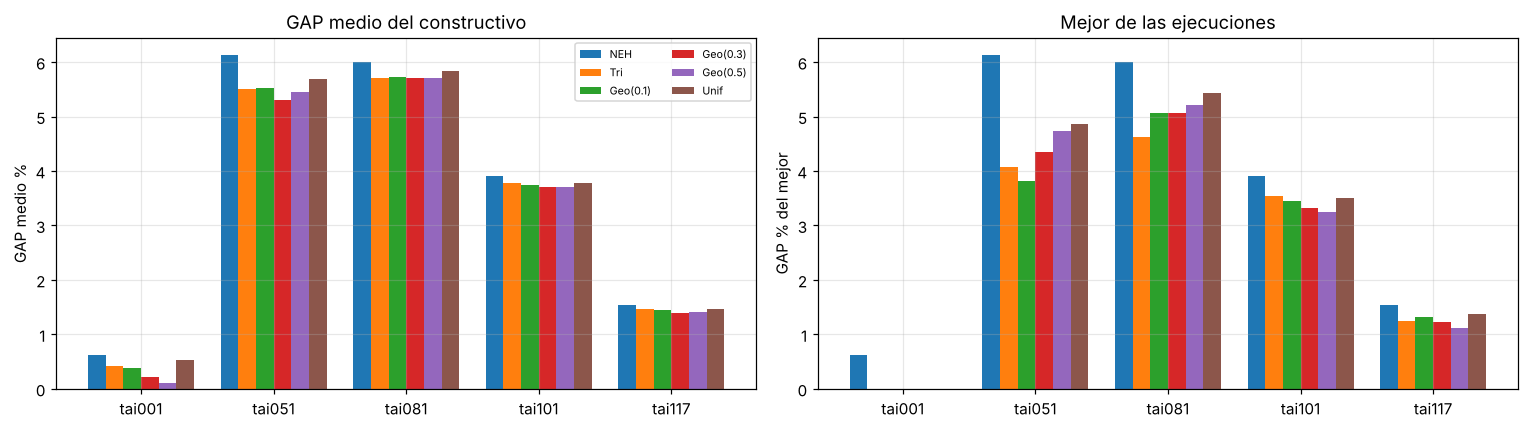

In [10]:
BAR_SET = ["NEH", "Tri", "Geo(0.1)", "Geo(0.3)", "Geo(0.5)", "Unif"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
x = np.arange(len(INSTANCES)); w = 0.8 / len(BAR_SET)
best = resA.pivot(index="dist", columns="instancia", values="gap_mejor")[INSTANCES]
for i, c in enumerate(BAR_SET):
    axes[0].bar(x + i * w, tabA.loc[c, INSTANCES].values, w, label=c)
    axes[1].bar(x + i * w, best.loc[c].values, w, label=c)
for ax in axes:
    ax.set_xticks(x + 0.4 - w / 2); ax.set_xticklabels([n.split("_")[0] for n in INSTANCES])
axes[0].set_ylabel("GAP medio %"); axes[0].set_title("GAP medio del constructivo"); axes[0].legend(fontsize=7, ncol=2)
axes[1].set_ylabel("GAP % del mejor"); axes[1].set_title("Mejor de las ejecuciones")
plt.tight_layout(); plt.show()

## 5. ILS-ESP completo

Pseudocódigo (diapositivas 43-44; la diapositiva escribe `localSearch(baseSol)` donde debe ir `currentSol`, lo corregimos):

```
baseSol = RandNEH();  baseSol = localSearch(baseSol);  bestSol = baseSol
while not endCondition:
    currentSol = enhancedSwap(baseSol)          # perturbación
    currentSol = localSearch(currentSol)
    delta = cost(currentSol) - cost(baseSol)
    if delta < 0:   baseSol = currentSol; lastImprovement = -delta; lastWasImp = True; actualiza bestSol
    elif delta > 0 and lastWasImp and delta <= lastImprovement:
                    baseSol = currentSol; lastWasImp = False        # Demon: degradación permitida
```
* **Enhanced swap**: dos posiciones al azar distintas, se intercambian y se hace *shift-to-left* (mejor posición hacia la izquierda, con Taillard) del trabajo en la posición menor y luego del de la mayor.
* **Búsqueda local**: inserción. Se recorren todos los trabajos en orden aleatorio; cada uno se extrae y se reinserta en su mejor posición (Taillard); se repite hasta que una pasada completa no mejora.
* **Sin parámetros**. El criterio de parada es el tiempo: `TIME_FACTOR · n · m` ms. El reloj se comprueba desde Python entre bloques de iteraciones (Numba no tiene `time` en modo nopython), así que la curva de convergencia se registra en esos puntos.

In [11]:
@njit(cache=True)
def local_search(p, perm, mk):
    # Búsqueda local por inserción (best-improvement por trabajo, recorrido aleatorio). In situ.
    n = perm.shape[0]
    improved = True
    while improved:
        improved = False
        jobs = np.random.permutation(n)
        for idx in range(n):
            job = jobs[idx]
            pos = 0
            while perm[pos] != job:
                pos += 1
            for t in range(pos, n - 1):          # llevar el trabajo al final...
                perm[t] = perm[t + 1]
            perm[n - 1] = job
            new_mk = insert_best_position(p, perm, n - 1)   # ...y reinsertarlo en su mejor posición
            if new_mk < mk:
                mk = new_mk
                improved = True
    return mk

@njit(cache=True)
def ils_esp_chunk(p, base, best, st, iters):
    # st = [makespan base, makespan best, lastImprovement, lastWasImprovement]
    n = base.shape[0]
    cur = base.copy()
    for _ in range(iters):
        cur[:] = base
        a = np.random.randint(0, n)
        b = np.random.randint(0, n)
        while b == a:
            b = np.random.randint(0, n)
        tmp = cur[a]; cur[a] = cur[b]; cur[b] = tmp          # intercambio
        lo = min(a, b); hi = max(a, b)
        insert_best_position(p, cur, lo)                     # shift-to-left ordenado
        insert_best_position(p, cur, hi)
        cur_mk = calc_makespan(p, cur, n)
        cur_mk = local_search(p, cur, cur_mk)
        delta = cur_mk - st[0]
        if delta < 0:
            st[3] = 1; st[2] = -delta
            base[:] = cur; st[0] = cur_mk
            if cur_mk < st[1]:
                best[:] = cur; st[1] = cur_mk
        elif delta > 0 and st[3] == 1 and delta <= st[2]:
            st[3] = 0
            base[:] = cur; st[0] = cur_mk

def ils_esp(p, kind, beta, budget_s, seed, order=None):
    # Devuelve dict con GAP-independiente: makespan inicial, tras LS, final, traza (t, best) e iteraciones.
    seed_numba(seed)
    order = tpt_order(p) if order is None else order
    t0 = time.perf_counter()
    base, mk0, _ = rand_neh_paper(p, order, kind, beta)   # RandNEH de la Fig. 6 (NEH si kind == NEH)
    base = base.copy()
    mk_ls = local_search(p, base, mk0)
    best = base.copy()
    st = np.array([mk_ls, mk_ls, 0, 0], dtype=np.int64)
    trace_t, trace_b = [time.perf_counter() - t0], [int(st[1])]
    iters, chunk = 0, 1
    while True:
        elapsed = time.perf_counter() - t0
        if elapsed >= budget_s:
            break
        c0 = time.perf_counter()
        ils_esp_chunk(p, base, best, st, chunk)
        iters += chunk
        dt = time.perf_counter() - c0
        trace_t.append(time.perf_counter() - t0); trace_b.append(int(st[1]))
        # bloques de ~20 ms o menos, y sin pasarse del presupuesto
        chunk = int(max(1, min(1000, 0.02 / max(dt / chunk, 1e-7))))
    return dict(mk_init=int(mk0), mk_ls=int(mk_ls), mk_final=int(st[1]), perm=best.copy(),
                trace_t=np.array(trace_t), trace_b=np.array(trace_b), iters=iters,
                time=time.perf_counter() - t0)

# calentamiento + comprobación de que el resultado es consistente
_p = P["tai051_50_20"]
r = ils_esp(_p, KIND_TRI, 0.0, 0.5, 1)
assert sorted(r["perm"]) == list(range(_p.shape[0])) and r["mk_final"] == makespan_slow(_p, r["perm"])
print(f"smoke test tai051: init {r['mk_init']} -> LS {r['mk_ls']} -> ILS-ESP {r['mk_final']}  ({r['iters']} iteraciones en {r['time']:.2f}s)")

smoke test tai051: init 4055 -> LS 3996 -> ILS-ESP 3996  (0 iteraciones en 0.87s)


## 6. Experimento B – ILS-ESP con distintas inicializaciones

Se mantiene el ILS-ESP intacto y solo se cambia la inicialización: `NEH` (determinista), `Tri` (la del algoritmo original), `Geo(0.1)`, `Geo(0.3)` y `Unif`, todas con el RandNEH de la Fig. 6. Cada combinación se ejecuta con `N_SEEDS_B` semillas independientes y presupuesto `TIME_FACTOR · n · m` ms (el mismo tiempo para todas, la construcción inicial incluida). Las ejecuciones se reparten en `N_PROCS` procesos; con presupuesto por tiempo real, la carga del equipo introduce algo de ruido entre ejecuciones.

In [12]:
INIT_SPEC = {"NEH": (KIND_NEH, 0.0), "Tri": (KIND_TRI, 0.0), "Geo(0.1)": (KIND_GEO, 0.1),
             "Geo(0.3)": (KIND_GEO, 0.3), "Unif": (KIND_UNIF, 0.0)}
INITS = list(INIT_SPEC)
GRID = np.linspace(0, 1, 101)       # fracción del presupuesto, para promediar curvas

def job_B(args):
    name, init, seed, budget = args
    p = P[name]
    kind, beta = INIT_SPEC[init]
    r = ils_esp(p, kind, beta, budget, seed)
    bks = BKS[name]
    # curva de convergencia: mejor makespan en cada fracción del presupuesto
    idx = np.searchsorted(r["trace_t"], GRID * budget, side="right") - 1
    curve = gap_pct(r["trace_b"][np.clip(idx, 0, None)], bks)
    assert r["mk_final"] == makespan_slow(p, r["perm"])
    return dict(instancia=name, init=init, seed=seed, budget_s=budget,
                gap_init=float(gap_pct(r["mk_init"], bks)), gap_tras_LS=float(gap_pct(r["mk_ls"], bks)),
                gap_final=float(gap_pct(r["mk_final"], bks)), makespan_final=r["mk_final"],
                iters=r["iters"], curve=curve)

tasks = []
for name in INSTANCES:
    n, m = P[name].shape
    budget = TIME_FACTOR * n * m / 1000.0
    for ii, init in enumerate(INITS):
        for s in range(N_SEEDS_B):
            tasks.append((name, init, BASE_SEED + 100 * ii + s, budget))
# las más largas primero para equilibrar los procesos
tasks.sort(key=lambda t: -t[3])
est = sum(t[3] for t in tasks) / N_PROCS
print(f"{len(tasks)} ejecuciones previstas; tiempo estimado ≈ {est/60:.1f} min con {N_PROCS} procesos"
      + ("" if RERUN else "  (RERUN=False: se leen los resultados guardados en results/)"))

250 ejecuciones previstas; tiempo estimado ≈ 14.2 min con 2 procesos  (RERUN=False: se leen los resultados guardados en results/)


In [13]:
CURVES_FILE = RESULTS_DIR / "expB_curvas.npz"
curves = {}
if RERUN:
    t0 = time.time()
    ctx = mp.get_context("fork")
    with ctx.Pool(N_PROCS) as pool:
        outB = pool.map(job_B, tasks, chunksize=1)
    print(f"hecho en {(time.time()-t0)/60:.1f} min")
    curves = {(o["instancia"], o["init"], o["seed"]): o.pop("curve") for o in outB}
    resB = pd.DataFrame(outB)
    resB.to_csv(RESULTS_DIR / "expB_ilsesp_raw.csv", index=False)
    np.savez_compressed(CURVES_FILE, **{f"{k[0]}|{k[1]}|{k[2]}": v for k, v in curves.items()})
else:   # resultados guardados de la última ejecución (se descartan las filas de la inicialización Tri-1c)
    resB = pd.read_csv(RESULTS_DIR / "expB_ilsesp_raw.csv")
    resB = resB[resB.init.isin(INITS)].copy()
    if CURVES_FILE.exists():
        z = np.load(CURVES_FILE)
        curves = {(k.split("|")[0], k.split("|")[1], int(k.split("|")[2])): z[k] for k in z.files}
resB.groupby(["instancia", "init"]).agg(gap_medio=("gap_final", "mean"), gap_mejor=("gap_final", "min"),
                                         gap_std=("gap_final", "std"), iters_medias=("iters", "mean")).round(3).head(10)

gap_medio  gap_mejor  gap_std  iters_medias
instancia    init                                                 
tai001_20_5  Geo(0.1)      0.000      0.000    0.000        4328.0
             Geo(0.3)      0.000      0.000    0.000        4562.0
             NEH           0.000      0.000    0.000        5184.1
             Tri           0.000      0.000    0.000        4627.9
             Unif          0.000      0.000    0.000        4924.7
tai051_50_20 Geo(0.1)      1.331      1.222    0.100        1448.8
             Geo(0.3)      1.334      1.222    0.140        1453.6
             NEH           1.303      1.222    0.088        1412.3
             Tri           1.225      0.650    0.223        1392.5
             Unif          1.115      0.754    0.237        1614.0

In [14]:
orderB = INITS
sumB = resB.groupby(["instancia", "init"]).agg(
    gap_init=("gap_init", "mean"), gap_tras_LS=("gap_tras_LS", "mean"),
    gap_final_medio=("gap_final", "mean"), gap_final_std=("gap_final", "std"),
    gap_final_mejor=("gap_final", "min"), iters=("iters", "mean")).reset_index()
sumB.to_csv(RESULTS_DIR / "expB_ilsesp_resumen.csv", index=False)
print("GAP final medio (%) de ILS-ESP — media de", N_SEEDS_B, "ejecuciones")
tab_mean = sumB.pivot(index="init", columns="instancia", values="gap_final_medio").reindex(orderB)[INSTANCES]
display(tab_mean.round(3))
print("Mejor GAP (%) entre las", N_SEEDS_B, "ejecuciones (equivale a N agentes en paralelo)")
display(sumB.pivot(index="init", columns="instancia", values="gap_final_mejor").reindex(orderB)[INSTANCES].round(3))
print("Iteraciones medias de ILS dentro del presupuesto")
display(sumB.pivot(index="init", columns="instancia", values="iters").reindex(orderB)[INSTANCES].round(0))

GAP final medio (%) de ILS-ESP — media de 10 ejecuciones


instancia,tai001_20_5,tai051_50_20,tai081_100_20,tai101_200_20,tai117_500_20
init,,,,,
NEH,0.0,1.303,2.431,1.755,0.542
Tri,0.0,1.225,2.134,1.714,0.573
Geo(0.1),0.0,1.331,2.152,1.782,0.592
Geo(0.3),0.0,1.334,2.196,1.752,0.641
Unif,0.0,1.115,2.291,1.740,0.621


Mejor GAP (%) entre las 10 ejecuciones (equivale a N agentes en paralelo)


instancia,tai001_20_5,tai051_50_20,tai081_100_20,tai101_200_20,tai117_500_20
init,,,,,
NEH,0.0,1.222,1.831,1.416,0.451
Tri,0.0,0.650,1.702,1.425,0.451
Geo(0.1),0.0,1.222,1.734,1.443,0.451
Geo(0.3),0.0,1.222,1.912,1.506,0.455
Unif,0.0,0.754,1.977,1.371,0.470


Iteraciones medias de ILS dentro del presupuesto


instancia,tai001_20_5,tai051_50_20,tai081_100_20,tai101_200_20,tai117_500_20
init,,,,,
NEH,5184.0,1412.0,632.0,341.0,252.0
Tri,4628.0,1392.0,671.0,350.0,251.0
Geo(0.1),4328.0,1449.0,673.0,336.0,262.0
Geo(0.3),4562.0,1454.0,634.0,337.0,277.0
Unif,4925.0,1614.0,655.0,350.0,222.0


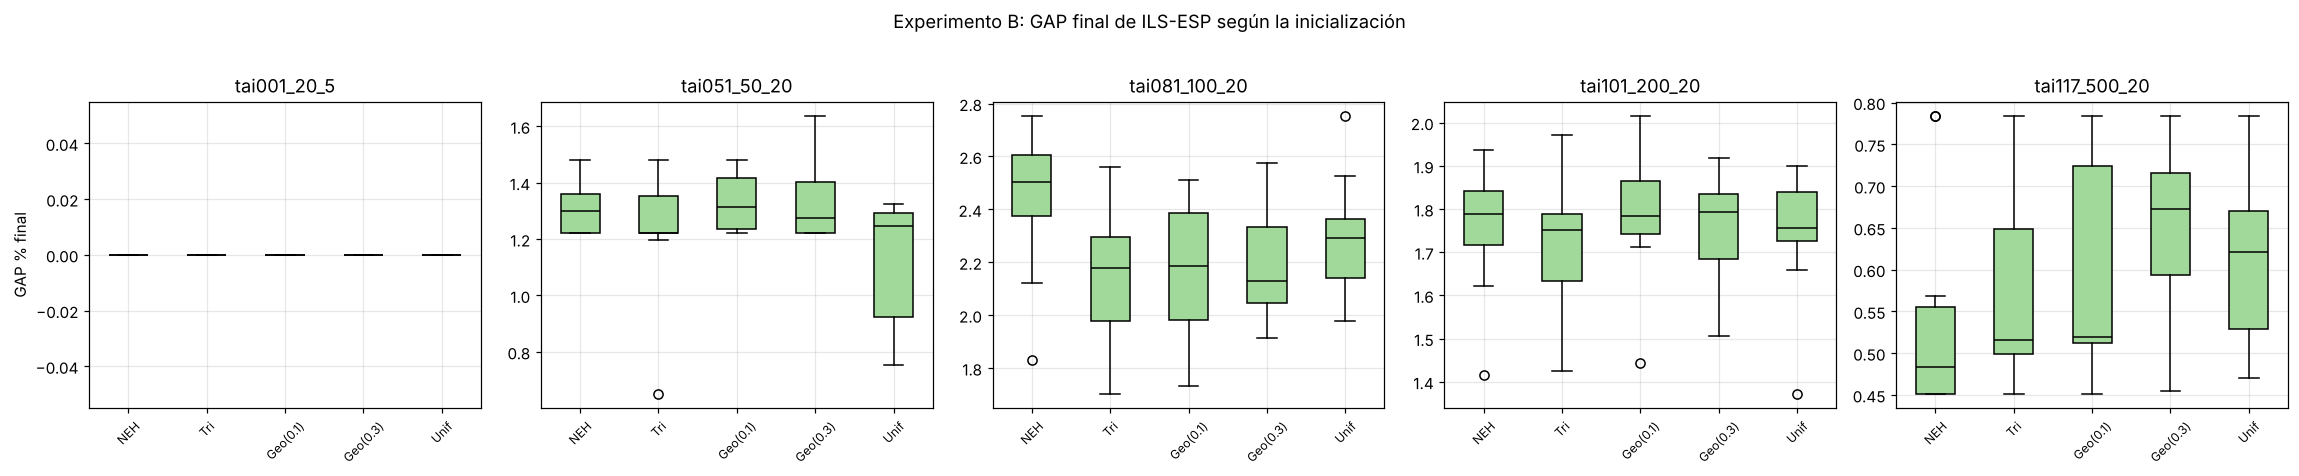

In [15]:
fig, axes = plt.subplots(1, 5, figsize=(21, 4.2))
for ax, name in zip(axes, INSTANCES):
    d = resB[resB.instancia == name]
    ax.boxplot([d[d.init == i].gap_final.values for i in orderB], tick_labels=orderB, patch_artist=True,
               boxprops=dict(facecolor="#a1d99b"), medianprops=dict(color="k"))
    ax.set_title(name); ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.set_ylabel("GAP % final" if name == INSTANCES[0] else "")
plt.suptitle("Experimento B: GAP final de ILS-ESP según la inicialización", y=1.02)
plt.tight_layout(); plt.show()

In [16]:
if not curves:
    print("Las curvas de convergencia no se guardaron en la ejecución anterior: se generarán en la próxima ejecución con RERUN = True.")
else:
    fig, axes = plt.subplots(1, 5, figsize=(19, 3.9))
    for ax, name in zip(axes, INSTANCES):
        for init in orderB:
            cs = np.array([curves[(name, init, s_)] for s_ in resB[(resB.instancia == name) & (resB.init == init)].seed])
            ax.plot(GRID, cs.mean(axis=0), label=init, lw=1.6)
        ax.set_title(name); ax.set_xlabel("fracción del presupuesto"); ax.set_yscale("log")
        ax.set_ylabel("GAP % medio del mejor" if name == INSTANCES[0] else "")
    axes[0].legend(fontsize=8)
    plt.suptitle("Convergencia de ILS-ESP (media de las semillas)", y=1.02)
    plt.tight_layout(); plt.show()

Las curvas de convergencia no se guardaron en la ejecución anterior: se generarán en la próxima ejecución con RERUN = True.


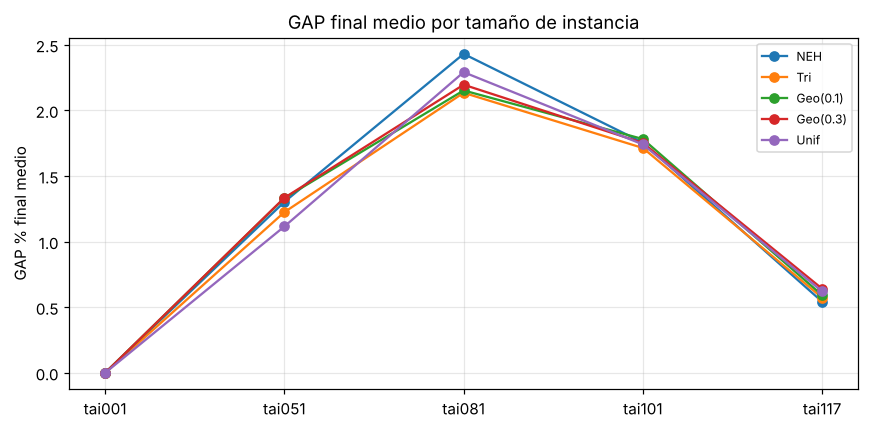

gap_init  gap_tras_LS  gap_final
instancia     init                                      
tai001_20_5   Geo(0.1)     0.446        0.423      0.000
              Geo(0.3)     0.282        0.133      0.000
              NEH          0.626        0.626      0.000
              Tri          0.454        0.407      0.000
              Unif         0.571        0.563      0.000
tai051_50_20  Geo(0.1)     5.616        3.957      1.331
              Geo(0.3)     5.616        3.939      1.334
              NEH          6.136        3.944      1.303
              Tri          5.725        4.210      1.225
              Unif         5.775        4.295      1.115
tai081_100_20 Geo(0.1)     5.685        4.238      2.152
              Geo(0.3)     5.777        4.430      2.196
              NEH          5.996        4.808      2.431
              Tri          5.798        4.408      2.134
              Unif         5.784        4.453      2.291
tai101_200_20 Geo(0.1)     3.799        2.751      1.782
              Geo(0.3)     3.751        2.684      1.752
              NEH          3.908        2.837      1.755
              Tri          3.820        2.745      1.714
              Unif         3.748        2.936      1.740
tai117_500_20 Geo(0.1)     1.424        0.912      0.592
              Geo(0.3)     1.458        1.036      0.641
              NEH          1.546        0.938      0.542
              Tri          1.462        1.060      0.573
              Unif         1.513        1.070      0.621

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
stages = ["gap_init", "gap_tras_LS", "gap_final"]
for init in orderB:
    d = resB[resB.init == init].groupby("instancia")[stages].mean().reindex(INSTANCES)
    ax.plot(range(len(INSTANCES)), d["gap_final"].values, "o-", label=init)
ax.set_xticks(range(len(INSTANCES))); ax.set_xticklabels([n.split("_")[0] for n in INSTANCES])
ax.set_ylabel("GAP % final medio"); ax.set_title("GAP final medio por tamaño de instancia"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# de dónde viene la mejora: constructivo -> búsqueda local -> ILS
stg = resB.groupby(["instancia", "init"])[stages].mean().round(3)
stg.loc[INSTANCES]

## 7. Significación estadística
Para cada instancia se compara el GAP final de cada inicialización con el de NEH determinista (test de Mann-Whitney, bilateral). Con 10 semillas por grupo, los p-valores son orientativos: no se corrigen por comparaciones múltiples. También se muestra el ranking medio (1 = mejor) de cada inicialización por instancia.

In [18]:
rows = []
for name in INSTANCES:
    base = resB[(resB.instancia == name) & (resB.init == "NEH")].gap_final.values
    for init in orderB[1:]:
        x = resB[(resB.instancia == name) & (resB.init == init)].gap_final.values
        if np.allclose(x, x[0]) and np.allclose(base, base[0]) and x[0] == base[0]:
            pval = 1.0
        else:
            pval = stats.mannwhitneyu(x, base, alternative="two-sided").pvalue
        rows.append(dict(instancia=name, init=init, dif_gap_medio_vs_NEH=x.mean() - base.mean(), p_valor=pval))
tests = pd.DataFrame(rows)
tests.to_csv(RESULTS_DIR / "expB_tests_vs_NEH.csv", index=False)
display(tests.pivot(index="init", columns="instancia", values="dif_gap_medio_vs_NEH").reindex(orderB[1:])[INSTANCES].round(3))
display(tests.pivot(index="init", columns="instancia", values="p_valor").reindex(orderB[1:])[INSTANCES].round(3))
rk = tab_mean.rank(axis=0)
rk["rank_medio"] = rk.mean(axis=1)
rk.round(2)

instancia,tai001_20_5,tai051_50_20,tai081_100_20,tai101_200_20,tai117_500_20
init,,,,,
Tri,0.0,-0.078,-0.297,-0.041,0.030
Geo(0.1),0.0,0.029,-0.279,0.027,0.050
Geo(0.3),0.0,0.031,-0.235,-0.003,0.099
Unif,0.0,-0.187,-0.139,-0.014,0.079


instancia,tai001_20_5,tai051_50_20,tai081_100_20,tai101_200_20,tai117_500_20
init,,,,,
Tri,1.0,0.346,0.017,0.405,0.285
Geo(0.1),1.0,0.560,0.041,0.850,0.179
Geo(0.3),1.0,0.754,0.041,0.910,0.087
Unif,1.0,0.126,0.104,0.705,0.067


instancia,tai001_20_5,tai051_50_20,tai081_100_20,tai101_200_20,tai117_500_20,rank_medio
init,,,,,,
NEH,3.0,3.0,5.0,4.0,1.0,3.2
Tri,3.0,2.0,1.0,1.0,2.0,1.8
Geo(0.1),3.0,4.0,2.0,5.0,3.0,3.4
Geo(0.3),3.0,5.0,3.0,3.0,5.0,3.8
Unif,3.0,1.0,4.0,2.0,4.0,2.8


## 8. Comparación global y conclusiones

In [19]:
# Resumen: NEH determinista -> RandNEH(Tri) -> ILS-ESP (Tri), GAP medio por instancia
summary = pd.DataFrame({
    "NEH (constructivo)": tabA.loc["NEH", INSTANCES],
    "RandNEH Tri (constructivo), media": tabA.loc["Tri", INSTANCES],
    "ILS-ESP desde NEH, media": tab_mean.loc["NEH", INSTANCES],
    "ILS-ESP desde Tri, media": tab_mean.loc["Tri", INSTANCES],
    "ILS-ESP desde Tri, mejor": sumB[sumB.init == "Tri"].set_index("instancia").loc[INSTANCES, "gap_final_mejor"],
})
summary.to_csv(RESULTS_DIR / "resumen_global.csv")
summary.round(3)

,NEH (constructivo),"RandNEH Tri (constructivo), media","ILS-ESP desde NEH, media","ILS-ESP desde Tri, media","ILS-ESP desde Tri, mejor"
instancia,,,,,
tai001_20_5,0.626,0.420,0.000,0.000,0.000
tai051_50_20,6.136,5.502,1.303,1.225,0.650
tai081_100_20,5.996,5.705,2.431,2.134,1.702
tai101_200_20,3.908,3.780,1.755,1.714,1.425
tai117_500_20,1.546,1.457,0.542,0.573,0.451


## Conclusiones
Resultados de la última ejecución completa (Experimento A: 30 ejecuciones del RandNEH de la Fig. 6 por distribución; Experimento B: 10 semillas por inicialización, ILS-ESP con 2 ms·n·m). El notebook lee esos resultados de `results/` (`RERUN = False`); las curvas de convergencia no se guardaron entonces y se generarán la próxima vez que se ejecute con `RERUN = True`.

**Experimento A – constructivo**
1. **El RandNEH de la Fig. 6 mejora al NEH en media en las cinco instancias.** GAP medio NEH → Tri: tai001 0,63 → 0,42; tai051 6,14 → 5,50; tai081 6,00 → 5,70; tai101 3,91 → 3,78; tai117 1,55 → 1,46. Con la triangular mejora al NEH en el 100 % de las ejecuciones en tai051, tai081, tai101 y tai117, y en el 50 % en tai001 (donde NEH ya está a 0,63 %).
2. **La mejora es modesta** (0,1–0,8 puntos de GAP): el bucle se para en la primera construcción que supera al NEH, que suele ser solo algo mejor. Hacen falta pocas construcciones (media 3 en tai051, 14–19 con la triangular en tai081/tai101, 9 en tai117).
3. **Las distribuciones se parecen mucho en calidad** (±0,2 puntos entre triangular y geométricas; p. ej. tai117: Tri 1,46, Geo(0,1) 1,46, Geo(0,3) 1,40; tai101: Tri 3,78, Geo(0,3) 3,70). Las geométricas con β entre 0,3 y 0,5 son ligeramente mejores en media en casi todas las instancias. La uniforme también mejora al NEH, pero no siempre (87 % de las ejecuciones en tai081 y 83 % en tai101).
4. **El coste sí las distingue.** Tiempo medio por ejecución en tai117: Geo(0,3) 39 ms, Geo(0,1) 46 ms, Tri 152 ms, Unif 1750 ms (115 construcciones de media). Cuanto más sesgo, antes aparece una construcción que bate al NEH; con `b = r` la triangular reparte mucha probabilidad en listas largas y necesita más intentos.

**Experimento B – ILS-ESP completo**
5. **La inicialización influye poco en el resultado final.** El GAP final medio de las cinco inicializaciones difiere en menos de 0,3 puntos en cada instancia, comparable a la desviación entre semillas (0,09–0,28). La ventaja del RandNEH en el punto de partida (p. ej. tai051: GAP inicial 5,73 con Tri frente a 6,14 con NEH) desaparece tras la búsqueda local (3,94 con NEH frente a 4,21 con Tri) y no se nota en el resultado del ILS.
6. **tai081 es la única instancia donde partir de una solución aleatorizada mejora de forma repetida.** Las cuatro inicializaciones aleatorizadas quedan por debajo de NEH (2,43 %) por 0,14–0,30 puntos (Tri 2,13; Geo(0,1) 2,15; Geo(0,3) 2,20; Unif 2,29), con p = 0,017 (Tri), 0,041 (Geo(0,1) y Geo(0,3)) y 0,104 (Unif) sin corregir por comparaciones múltiples (20 contrastes; con Bonferroni ninguno sería significativo). Es un indicio, no una prueba.
7. **En tai117, NEH como inicio fue el mejor en media (0,54 %)**, con las demás entre 0,57 y 0,64 % (p 0,07–0,29, no significativo). Plausible: con ~250 iteraciones de ILS, partir de NEH pesa más que diversificar.
8. **En el resto (tai001, tai051, tai101) no hay diferencias apreciables**: tai001 se resuelve (GAP 0) en las 50 ejecuciones con cualquier inicialización. El ranking medio (1 = mejor) queda: NEH 3,2; Tri 1,8; Geo(0,1) 3,4; Geo(0,3) 3,8; Unif 2,8. La triangular es la mejor de las cinco en media en tai081 y tai101, pero con diferencias dentro del ruido.
9. **GAP final medio con ILS-ESP desde Tri, 2 ms·n·m:** tai001 0,00 %, tai051 1,23 %, tai081 2,13 %, tai101 1,71 %, tai117 0,57 %; mejor de 10 ejecuciones: 0,00 / 0,65 / 1,70 / 1,43 / 0,45 %. El paper usa 10 ms·n·m y promedia 10 instancias por conjunto, así que no es una comparación directa.

**Conclusión sobre el RandNEH:** aplicarlo como en el paper hace que el constructivo nunca sea peor que NEH y que lo mejore en casi todas las ejecuciones, pero no cambia lo esencial del ILS-ESP completo: con este presupuesto el resultado final depende sobre todo de la búsqueda local y el ILS, no de la solución de partida. La ventaja de la diversificación que defiende el paper se vería con varios agentes en paralelo y presupuestos mayores (el paper usa 10 ms·n·m y hasta 80 réplicas), que aquí no se han podido probar con 2 núcleos.

**Limitaciones**
* Presupuesto por tiempo real con 2 procesos en 2 núcleos: ruido de 0,1–0,2 puntos en medias de 10 semillas, sin reproducibilidad bit a bit. Como referencia, la misma configuración (triangular con una sola construcción) dio 0,71 % y 0,63 % en tai117 en dos ejecuciones distintas (resultados antiguos en `results/v1_una_construccion/`).
* 10 semillas por celda es poco para diferencias de ~0,1–0,3 puntos; con 20 contrastes sin corregir, los p < 0,05 deben leerse como indicios.
* La búsqueda local es la inserción tipo Ruiz-Stützle según mi recuerdo; el paper solo dice "traditional local search" y no la detalla.
* BKS de tai001, tai051 y tai081 son mejores conocidos, no óptimos demostrados.
* Con el bucle de la Fig. 6, la diversidad entre agentes es menor que con una construcción sesgada libre (la primera que bate a NEH suele ser parecida).